# Comprendre et simuler les retraites en France

Ce carnet interactif permet d'explorer les chiffres officiels des retraites en France et de tester facilement différents scénarios de réforme.

Il s'appuie sur le module [`analyse_retraites.py`](./analyse_retraites.py), qui se connecte directement aux bases de données publiques :
- **La DREES** (le service statistique du ministère des Solidarités et de la Santé) : elle publie les comptes complets de la protection sociale (jusqu'en 2024), la répartition des pensions et les âges de départ.
- **Eurostat** (l'office statistique européen) : il fournit la pyramide des âges exacte de la France en 2025 (nombre de naissances et d'habitants à chaque âge).

### Comment est organisé ce document ?
1. **Chargement des données** depuis les serveurs publics (avec sauvegarde locale pour travailler rapidement).
2. **La facture globale** : combien la France dépense-t-elle au total chaque année, et pour quoi ?
3. **Secteur public et ministères** : les retraites des fonctionnaires et de chaque ministère sont-elles bien comptées ?
4. **Qui touche combien, et quand ?** : la répartition des pensions des plus modestes aux plus élevées, et l'âge réel de départ.
5. **Simulateur « Minimum / Maximum »** : quel est le coût ou le gain si l'on fixe un plancher ou un plafond aux retraites actuelles ?
6. **Simulateur « Capitalisation »** : combien toucherait chaque génération (des nouveau-nés jusqu'aux seniors) si une partie des cotisations était placée en épargne ?


## 1. Connexion aux bases de données officielles

La cellule ci-dessous charge toutes les séries statistiques officielles.
Par défaut, elle utilise les fichiers déjà téléchargés dans le dossier `cache_api/` pour un affichage instantané. Si vous voulez forcer une mise à jour directe depuis Internet, remplacez simplement `refresh_cache=False` par `refresh_cache=True`.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from analyse_retraites import (
    ConnecteurDonneesRetraites,
    ParametresReformeRepartition,
    ParametresCapitalisation,
    construire_micro_points,
    calculer_indicateurs_distribution,
    construire_tableau_fonction_publique,
    construire_ventilation_ministeres,
    simuler_reforme_repartition,
    trouver_plafond_equilibre,
    simuler_cohorte_individuelle,
    simuler_tranches_age_eurostat,
    simuler_trajectoire_macro_transition,
    tracer_distribution_min_max,
)

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
plt.style.use("seaborn-v0_8-whitegrid")

# Passer refresh_cache=True pour re-télécharger en direct depuis les APIs DREES & Eurostat
connecteur = ConnecteurDonneesRetraites(refresh_cache=False)
donnees = connecteur.charger_tout()

print(f"Exercice macro DREES     : {donnees.annee_cps} | Pyramide des âges Eurostat : {donnees.annee_eurostat}")
print(f"Total pensions strictes  : {donnees.masse_pensions_brut_mde:.1f} Md€/an (ratio net/brut = {donnees.ratio_net_brut:.1%})")
print(f"Nombre de retraités      : {donnees.effectif_total_retraites_k/1000:.2f} millions (dont {donnees.effectif_droit_direct_k/1000:.2f} M avec une retraite personnelle)")
display(pd.DataFrame(list(donnees.provenance.items()), columns=["Source officielle", "Mode de chargement"]))


Exercice macro DREES     : 2024 | Pyramide des âges Eurostat : 2025
Total pensions strictes  : 406.0 Md€/an (ratio net/brut = 90.5%)
Nombre de retraités      : 17.89 millions (dont 16.97 M avec une retraite personnelle)


,Source officielle,Mode de chargement
0,cps_latest_year,Cache local (cps_latest_year.json)
1,cps_prestations_2024,Cache local (cps_prestations_2024.json)
2,cps_regimes_2024,Cache local (cps_regimes_2024.json)
3,age_depart_drees,Cache local (age_depart_drees.json)
4,rec02_carriere_complete,Cache local (rec02_carriere_complete.json)
5,taux_remplacement_cc,Cache local (taux_remplacement_cc.json)
6,eir2020_xlsx,Cache local (eir2020_xlsx.xlsx)
7,effectifs_2022_xlsx,Cache local (effectifs_2022_xlsx.xlsx)
8,distrib_age_2017_xlsx,Cache local (distrib_age_2017_xlsx.xlsx)
9,eurostat_pop_fr,Cache local (eurostat_pop_fr.json)


## 2. La dépense globale : combien coûtent les retraites au total ?

Avant de regarder dans le détail, il est utile de distinguer deux chiffres souvent cités dans les médias :
- **Les pensions de retraite à proprement parler (~406 Md€/an)** : ce sont les sommes versées chaque mois aux retraités. Elles regroupent :
  - les **pensions de droit direct** (~359 Md€) : la retraite que chacun a acquise par ses propres cotisations ;
  - les **pensions de droit dérivé ou « réversion »** (~42 Md€) : la part de retraite reversée au conjoint survivant après un décès ;
  - le **minimum vieillesse / ASPA** (~5 Md€) : l'aide versée aux personnes âgées ayant de très faibles ressources.
- **L'ensemble du risque « Vieillesse-Survie » (~427 Md€/an)** : en plus des pensions, ce grand total ajoute notamment les aides à la **dépendance** (comme l'APA pour financer le maintien à domicile ou l'EHPAD, soit ~12 Md€) et certaines indemnités de départ.


In [2]:
df_niv3 = (
    donnees.cps_prestations[donnees.cps_prestations["ps_niveau"].astype(str) == "3"]
    [["ps_code", "ps_lib", "montant_mde"]]
    .sort_values("montant_mde", ascending=False)
    .reset_index(drop=True)
)
total_vs = float(donnees.cps_prestations[donnees.cps_prestations["ps_code"] == "E11-2"]["montant_mde"].sum())
df_niv3["part_pct"] = 100.0 * df_niv3["montant_mde"] / total_vs
print(f"Total Vieillesse-Survie ({donnees.annee_cps}) : {total_vs:.2f} Md€ | Dont pensions strictes : {donnees.masse_pensions_brut_mde:.2f} Md€")
display(df_niv3.style.format({"montant_mde": "{:.2f} Md€", "part_pct": "{:.1f} %"}))

df_org = donnees.cps_regimes[["si_code", "regime_nom", "montant_mde"]].head(12).copy()
df_org["part_pct"] = 100.0 * df_org["montant_mde"] / donnees.cps_regimes["montant_mde"].sum()
display(df_org.style.format({"montant_mde": "{:.2f} Md€", "part_pct": "{:.1f} %"}))


Total Vieillesse-Survie (2024) : 426.70 Md€ | Dont pensions strictes : 406.02 Md€


,ps_code,ps_lib,montant_mde,part_pct
0,E11-21.1,Pensions de droit direct,359.37 Md€,84.2 %
1,E11-22.1,Pensions de droit dérivé,41.70 Md€,9.8 %
2,E11-21.4,Prestations liées à la dépendance,11.81 Md€,2.8 %
3,E11-21.2,Minimum vieillesse,4.94 Md€,1.2 %
4,E11-21.9,Autres prestations vieillesse,4.11 Md€,1.0 %
5,E11-22.9,Autres prestations survie,3.38 Md€,0.8 %
6,E11-21.3,Indemnités de départ à la retraite (organismes d'assurance…),1.38 Md€,0.3 %


,si_code,regime_nom,montant_mde,part_pct
0,S13141,Caisse nationale d’assurance vieillesse,163.35 Md€,38.3 %
1,S13141,Association générale des institutions de retraite des cadres et association des régimes de retraite complémentaire des salariés,98.31 Md€,23.0 %
2,S13111,Régimes pour les agents de l'État (y compris ex-L),64.65 Md€,15.2 %
3,S13141,Autres régimes spéciaux,38.89 Md€,9.1 %
4,S13141,Exploitants agricoles,10.62 Md€,2.5 %
5,S1313,Régime d'intervention sociale des départements,10.54 Md€,2.5 %
6,S13141,CNAVPL base complementaire,8.84 Md€,2.1 %
7,S13141,Régime des salariés agricoles,5.38 Md€,1.3 %
8,S11_S12A,Autres régimes privés,4.95 Md€,1.2 %
9,S12_OA,Entreprises d'assurance - contrats collectifs,4.56 Md€,1.1 %


## 3. Les retraites des fonctions publiques et des ministères sont-elles comptées ?

**Oui, à 100 %.** Les **406 Md€** de pensions incluent l'ensemble des retraités du secteur privé **et** de toute la sphère publique :
1. **Les fonctionnaires de l'État** (civils des ministères + militaires) : **64,65 Md€** en 2024 (incluant également les anciens fonctionnaires de La Poste et d'Orange).
2. **Les fonctionnaires territoriaux et hospitaliers (CNRACL)** (mairies, départements, régions, hôpitaux publics) et les ouvriers d'État (FSPOEIE) : ils représentent environ **27 Md€** (comptabilisés avec la SNCF, la RATP ou les industries électriques dans la ligne « Autres régimes spéciaux » de 38,89 Md€).
3. **Les agents contractuels publics (IRCANTEC)** : **4,33 Md€** pour leur retraite complémentaire (en plus de leur retraite de base CNAV).
4. **La retraite additionnelle sur primes (ERAFP)** : **0,43 Md€** versés sous forme de rente ou capital par capitalisation.

### Attention à ne pas compter les dépenses des ministères en double !
Dans le budget annuel de l'État, chaque ministère (Éducation nationale, Intérieur, Armées, Justice…) inscrit dans ses dépenses de personnel une forte « cotisation employeur » destinée à alimenter la caisse des retraites de l'État (*CAS Pensions*).
- **Ce n'est pas une dépense supplémentaire** : cet argent versé par les ministères est la *recette* qui sert précisément à payer les **64,65 Md€** de pensions des fonctionnaires retraités — qui sont **déjà inclus dans les 406 Md€**.

Les deux tableaux et graphiques ci-dessous montrent d'abord la dépense globale Public/Privé, puis le **détail estimé ministère par ministère** (d'après les clés budgétaires du Projet de Loi de Finances appliquées à l'enveloppe DREES 2024).


=== DÉPENSE TOTALE POUR LES RETRAITES EN FRANCE (2024, DREES CPS) ===
  - Total Vieillesse-Survie (incl. dépendance APA/hébergement & indemnités) : 426.70 Md€/an
  - Total Pensions strictes (direct + réversion + minimum vieillesse)       : 406.02 Md€/an bruts (≈ 367.4 Md€/an nets)
  - Effectifs couverts                                                      : 17.89 M retraités (16.97 M de droit direct)


,Regime / Caisse,Pensionnes caisse (k),Regime principal (k),Pension caisse (€ brut),Pension totale tous reg. (€ brut),Carr. complete (€ brut),Masse droit direct est. (Md€),Enveloppe CPS 2024
0,Fonction publique civile de l'État (SRE),"1,628","1,550","2,200 €","2,400 €","2,580 €",43.0 Md€,"64,65 Md€ (État civils+milit.)"
1,Fonction publique militaire de l'État (SRE),373,340,"1,800 €","2,140 €","2,730 €",8.1 Md€,"(inclus dans les 64,65 Md€ État)"
2,Territoriale & Hospitalière (CNRACL),"1,314","1,080","1,390 €","1,730 €","1,870 €",21.9 Md€,"Inclus ds « Autres rég. spéciaux » (38,89 Md€)"
3,Ouvriers des établissements de l'État (FSPOEIE),64,—,"2,004 €",—,—,1.5 Md€,"Inclus ds « Autres rég. spéciaux » (38,89 Md€)"
4,Contractuels publics — Complémentaire (IRCANTEC),"2,012",—,135 €,—,—,3.3 Md€,4.33 Md€
5,Retraite additionnelle FP sur primes (ERAFP),454,—,32 €,—,—,0.2 Md€,0.43 Md€
6,Comparatif Privé — Base (CNAV / ex-SSI),"14,389","11,890",721 €,"1,490 €","1,870 €",124.5 Md€,163.35 Md€
7,Comparatif Privé — Complém. (Agirc-Arrco),"12,387",—,502 €,—,—,74.6 Md€,98.31 Md€
8,Sous-total Sphère Fonction Publique (titulaires+contract.),—,"2,970",—,—,—,77.9 Md€,~95 Md€ (État + CNRACL + IRCANTEC + ERAFP)
9,Sous-total Secteur Privé (CNAV + Agirc-Arrco),—,"11,890",—,—,—,199.1 Md€,163.35 Md€ + 98.31 Md€



=== VENTILATION PAR MINISTÈRE DES PENSIONS DE L'ÉTAT (64,65 Md€ / an, inclus dans les 406 Md€) ===


,Ministère / Périmètre d'origine,Dépense pensions (Md€/an),Part des pensions État (%),Part du total retraites France (%),Effectif estimé (k pensionnés),Repère budgétaire PLF
0,Éducation nationale & Enseignement supérieur,28.45 Md€,44.0 %,7.0 %,880,~32 % du budget du ministère
1,"Intérieur (Police nationale, Gendarmerie, Préfectures)",10.34 Md€,16.0 %,2.5 %,320,~30 % du budget du ministère
2,Armées (Militaires & personnels civils Défense),9.37 Md€,14.5 %,2.3 %,290,~12 % du budget du ministère
3,Anciens fonctionnaires La Poste & Orange (« ex-L »),5.17 Md€,8.0 %,1.3 %,160,Contributions dédiées (hors budget État)
4,"Économie & Finances (DGFiP, Douanes, Insee)",4.85 Md€,7.5 %,1.2 %,150,Agents financiers & fiscaux
5,"Justice (Magistrats, greffes, pénitentiaire)",2.78 Md€,4.3 %,0.7 %,86,~21 % du budget du ministère
6,"Autres ministères (Écologie, Agriculture, Santé, Culture…)",3.69 Md€,5.7 %,0.9 %,114,Moyenne interministérielle ~13 %
7,TOTAL PENSIONS DE L'ÉTAT (CPS 2024),64.65 Md€,100.0 %,15.9 %,"2,001",Inclus dans les 406.02 Md€ France


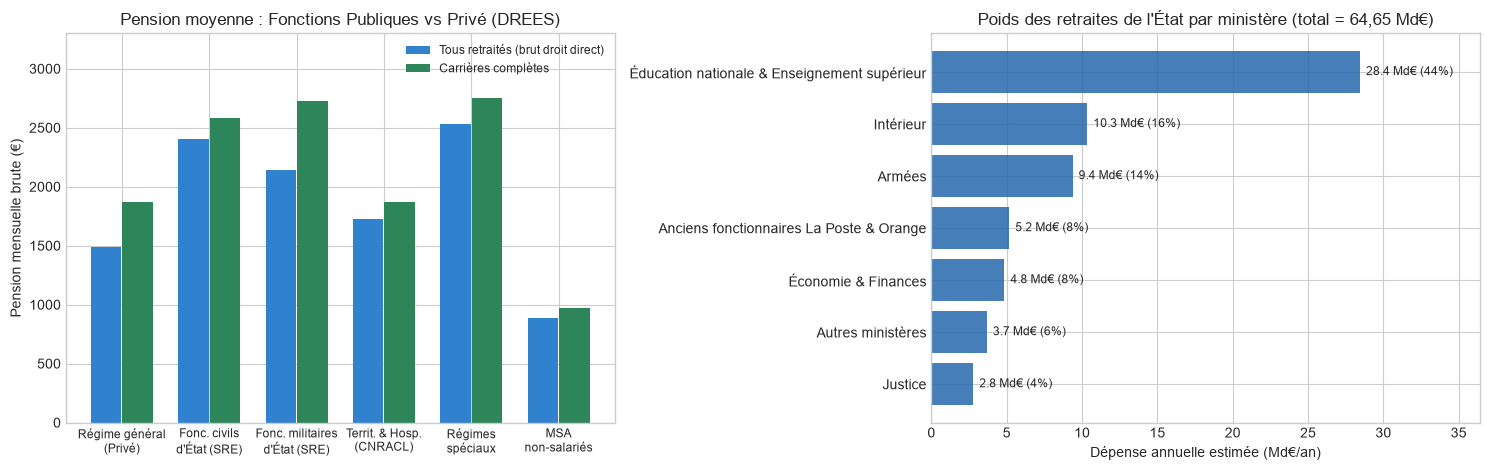

In [3]:
total_vs = float(donnees.cps_prestations[donnees.cps_prestations["ps_code"] == "E11-2"]["montant_mde"].sum())
masse_nette_mde = donnees.masse_pensions_brut_mde * donnees.ratio_net_brut
print(f"=== DÉPENSE TOTALE POUR LES RETRAITES EN FRANCE ({donnees.annee_cps}, DREES CPS) ===")
print(f"  - Total Vieillesse-Survie (incl. dépendance APA/hébergement & indemnités) : {total_vs:.2f} Md€/an")
print(f"  - Total Pensions strictes (direct + réversion + minimum vieillesse)       : {donnees.masse_pensions_brut_mde:.2f} Md€/an bruts (≈ {masse_nette_mde:.1f} Md€/an nets)")
print(f"  - Effectifs couverts                                                      : {donnees.effectif_total_retraites_k/1000:.2f} M retraités ({donnees.effectif_droit_direct_k/1000:.2f} M de droit direct)")

# Tableau 1 : Public vs Privé et TOTAL GÉNÉRAL
df_fp = construire_tableau_fonction_publique(donnees)
display(
    df_fp.style.format(
        {
            "Pensionnes caisse (k)": "{:,.0f}",
            "Regime principal (k)": "{:,.0f}",
            "Pension caisse (€ brut)": "{:,.0f} €",
            "Pension totale tous reg. (€ brut)": "{:,.0f} €",
            "Carr. complete (€ brut)": "{:,.0f} €",
            "Masse droit direct est. (Md€)": "{:.1f} Md€",
        },
        na_rep="—",
    ).apply(
        lambda row: ["font-weight: bold; background-color: #edf2f7" if "TOTAL" in str(row["Regime / Caisse"]) or "Sous-total" in str(row["Regime / Caisse"]) else "" for _ in row],
        axis=1,
    )
)

# Tableau 2 : Ventilation indicative par ministère (sur les 64,65 Md€ de l'État)
print("\n=== VENTILATION PAR MINISTÈRE DES PENSIONS DE L'ÉTAT (64,65 Md€ / an, inclus dans les 406 Md€) ===")
df_min = construire_ventilation_ministeres(donnees)
display(
    df_min.style.format(
        {
            "Dépense pensions (Md€/an)": "{:.2f} Md€",
            "Part des pensions État (%)": "{:.1f} %",
            "Part du total retraites France (%)": "{:.1f} %",
            "Effectif estimé (k pensionnés)": "{:,.0f}",
        }
    ).apply(
        lambda row: ["font-weight: bold; background-color: #edf2f7" if "TOTAL" in str(row["Ministère / Périmètre d'origine"]) else "" for _ in row],
        axis=1,
    )
)

# Graphiques comparatifs : Public vs Privé + Dépense par ministère
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8))

reg_plot = donnees.pensions_par_regime.iloc[[2, 4, 5, 7, 8, 10]].copy()
reg_plot["nom_court"] = [
    "Régime général\n(Privé)",
    "Fonc. civils\nd'État (SRE)",
    "Fonc. militaires\nd'État (SRE)",
    "Territ. & Hosp.\n(CNRACL)",
    "Régimes\nspéciaux",
    "MSA\nnon-salariés",
]
x = np.arange(len(reg_plot))
ax1.bar(x - 0.18, reg_plot["tous_ensemble"], width=0.35, color="#3182ce", label="Tous retraités (brut droit direct)")
ax1.bar(x + 0.18, reg_plot["cc_ensemble"], width=0.35, color="#2f855a", label="Carrières complètes")
ax1.set_xticks(x)
ax1.set_xticklabels(reg_plot["nom_court"], fontsize=8.5)
ax1.set_ylim(0, 3300)
ax1.set_ylabel("Pension mensuelle brute (€)")
ax1.set_title("Pension moyenne : Fonctions Publiques vs Privé (DREES)")
ax1.legend(loc="upper right", fontsize=8.5)

min_plot = df_min.iloc[:-1].sort_values("Dépense pensions (Md€/an)", ascending=True)
bars = ax2.barh(
    [m.split(" (")[0] for m in min_plot["Ministère / Périmètre d'origine"]],
    min_plot["Dépense pensions (Md€/an)"],
    color="#2b6cb0",
    alpha=0.88,
)
for bar, val, pct in zip(bars, min_plot["Dépense pensions (Md€/an)"], min_plot["Part des pensions État (%)"]):
    ax2.text(val + 0.4, bar.get_y() + bar.get_height() / 2, f"{val:.1f} Md€ ({pct:.0f}%)", va="center", fontsize=8.5)
ax2.set_xlim(0, float(min_plot["Dépense pensions (Md€/an)"].max()) * 1.28)
ax2.set_xlabel("Dépense annuelle estimée (Md€/an)")
ax2.set_title("Poids des retraites de l'État par ministère (total = 64,65 Md€)")
plt.tight_layout()
plt.show()


## 4. Qui touche combien, et à quel âge part-on ?

Pour bien lire les montants ci-dessous :
- Les sommes sont exprimées en **euros nets par mois** (ce qui arrive réellement sur le compte bancaire après déduction des prélèvements sociaux comme la CSG et la CRDS, soit environ 9,5 % en moyenne).
- La **moyenne** (~1 711 €) est tirée vers le haut par les plus grosses pensions, alors que la **médiane** (~1 594 €) correspond exactement au retraité « du milieu » : la moitié des retraités touche moins, l'autre moitié touche plus.
- **D1** désigne le seuil en dessous duquel se situent les 10 % de retraites les plus basses ; **D9** désigne le seuil au-dessus duquel se trouvent les 10 % de retraites les plus élevées.
- On observe aussi que les **petites pensions (< 800 €)** concernent souvent des personnes ayant eu une carrière très courte en France (ou ayant travaillé principalement à l'étranger), et ne pèsent au final que **3,8 %** de la dépense totale.


Indicateurs 2024 -> Moyenne : 1,711 € | Médiane : 1,594 € | D1 (10% les plus bas) : 468 € | D9 (10% les plus hauts) : 2,934 € | Rapport D9/D1 : 6.27 | Gini : 0.323


,Tranche mensuelle nette,Retraités (k),% Population,Masse annuelle (Md€),% Masse
0,Moins de 800 €,"2,952",16.5 %,13.9 Md€,3.8 %
1,800 à 1 200 €,"3,123",17.5 %,38.8 Md€,10.6 %
2,1 200 à 1 600 €,"2,875",16.1 %,49.4 Md€,13.4 %
3,1 600 à 2 000 €,"3,519",19.7 %,76.6 Md€,20.9 %
4,2 000 à 2 500 €,"2,428",13.6 %,65.8 Md€,17.9 %
5,2 500 à 3 000 €,"1,272",7.1 %,41.5 Md€,11.3 %
6,3 000 à 4 000 €,"1,134",6.3 %,45.9 Md€,12.5 %
7,Plus de 4 000 €,592,3.3 %,35.6 Md€,9.7 %


,Tranche âge actuel,Effectif estimé (k),Ensemble (€ brut),Femmes (€ brut),Hommes (€ brut),Masse droit direct (Md€)
0,Moins de 60 ans,384,"1,716 €","1,411 €","1,899 €",7.9 Md€
1,60 - 64 ans,"2,808","1,685 €","1,451 €","1,896 €",56.8 Md€
2,65 - 69 ans,"4,525","1,677 €","1,401 €","1,976 €",91.0 Md€
3,70 - 74 ans,"3,435","1,677 €","1,342 €","2,057 €",69.1 Md€
4,75 - 79 ans,"2,281","1,696 €","1,278 €","2,193 €",46.4 Md€
5,80 - 84 ans,"1,740","1,590 €","1,146 €","2,175 €",33.2 Md€
6,85 ans et plus,"1,802","1,356 €",955 €,"2,129 €",29.3 Md€


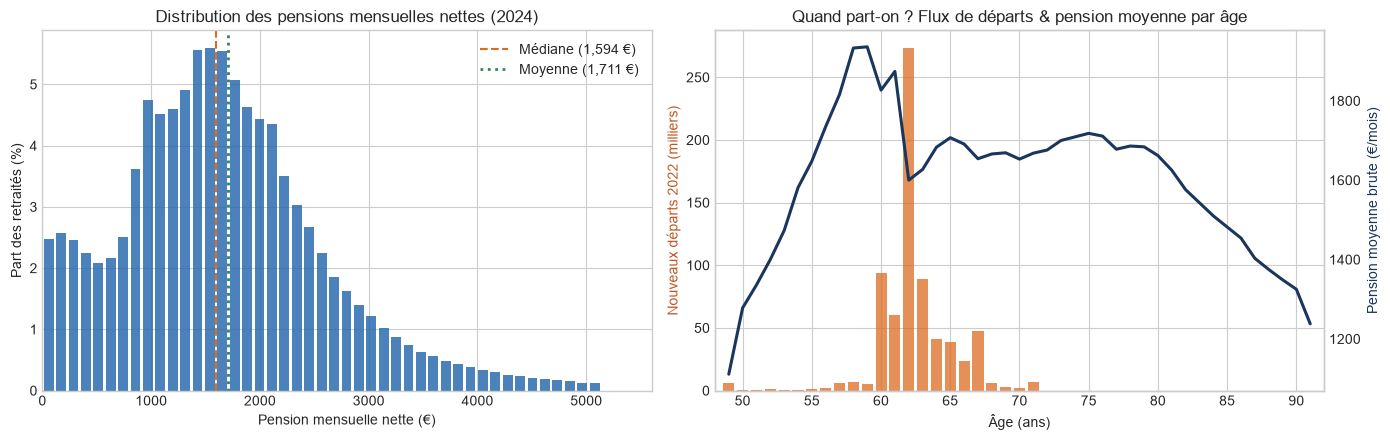

In [4]:
df_d = donnees.distrib_pensions_2024
tranches_macro = [
    ("Moins de 800 €", 0, 800),
    ("800 à 1 200 €", 800, 1200),
    ("1 200 à 1 600 €", 1200, 1600),
    ("1 600 à 2 000 €", 1600, 2000),
    ("2 000 à 2 500 €", 2000, 2500),
    ("2 500 à 3 000 €", 2500, 3000),
    ("3 000 à 4 000 €", 3000, 4000),
    ("Plus de 4 000 €", 4000, 1e9),
]
eff_tot = float(df_d["effectifs_k"].sum())
masse_tot = float(df_d["masse_nette_mde"].sum())

rows_qtc = []
for lbl, lo, hi in tranches_macro:
    sub = df_d[(df_d["centre_2024"] >= lo) & (df_d["centre_2024"] < hi)]
    eff = float(sub["effectifs_k"].sum())
    masse = float(sub["masse_nette_mde"].sum())
    rows_qtc.append(
        {
            "Tranche mensuelle nette": lbl,
            "Retraités (k)": eff,
            "% Population": 100.0 * eff / eff_tot,
            "Masse annuelle (Md€)": masse,
            "% Masse": 100.0 * masse / masse_tot,
        }
    )
df_qtc = pd.DataFrame(rows_qtc)

micro = construire_micro_points(df_d)
stats = calculer_indicateurs_distribution(micro["montants"], micro["w_cc"] + micro["w_incomp"])
print(
    f"Indicateurs {donnees.annee_cps} -> Moyenne : {stats['moyenne']:,.0f} € | "
    f"Médiane : {stats['mediane']:,.0f} € | D1 (10% les plus bas) : {stats['d1']:,.0f} € | "
    f"D9 (10% les plus hauts) : {stats['d9']:,.0f} € | Rapport D9/D1 : {stats['ratio_d9_d1']:.2f} | Gini : {stats['gini']:.3f}"
)
display(
    df_qtc.style.format(
        {
            "Retraités (k)": "{:,.0f}",
            "% Population": "{:.1f} %",
            "Masse annuelle (Md€)": "{:.1f} Md€",
            "% Masse": "{:.1f} %",
        }
    )
)

# Tableau par âge actuel
df_pa = donnees.pensions_par_age
tranches_act = [
    ("Moins de 60 ans", 0, 59), ("60 - 64 ans", 60, 64), ("65 - 69 ans", 65, 69),
    ("70 - 74 ans", 70, 74), ("75 - 79 ans", 75, 79), ("80 - 84 ans", 80, 84), ("85 ans et plus", 85, 120),
]
rows_age = []
for lbl, a_min, a_max in tranches_act:
    sub = df_pa[(df_pa["age_num"] >= a_min) & (df_pa["age_num"] <= a_max)]
    w = sub["effectif_estime_k"].values
    w_s = float(np.sum(w))
    m_ens = float(np.average(sub["pension_brut_ensemble"], weights=w))
    rows_age.append(
        {
            "Tranche âge actuel": lbl,
            "Effectif estimé (k)": w_s,
            "Ensemble (€ brut)": m_ens,
            "Femmes (€ brut)": float(np.average(sub["pension_brut_femmes"], weights=w)),
            "Hommes (€ brut)": float(np.average(sub["pension_brut_hommes"], weights=w)),
            "Masse droit direct (Md€)": (w_s * 1000.0 * m_ens * 12.0) / 1e9,
        }
    )
display(
    pd.DataFrame(rows_age).style.format(
        {
            "Effectif estimé (k)": "{:,.0f}",
            "Ensemble (€ brut)": "{:,.0f} €",
            "Femmes (€ brut)": "{:,.0f} €",
            "Hommes (€ brut)": "{:,.0f} €",
            "Masse droit direct (Md€)": "{:.1f} Md€",
        }
    )
)

# Graphique « Qui touche combien, quand ? »
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.bar(df_d["centre_2024"], df_d["pct_ensemble_all"], width=90, color="#2b6cb0", alpha=0.85)
ax1.axvline(stats["mediane"], color="#dd6b20", linestyle="--", label=f"Médiane ({stats['mediane']:,.0f} €)")
ax1.axvline(stats["moyenne"], color="#2f855a", linestyle=":", linewidth=2, label=f"Moyenne ({stats['moyenne']:,.0f} €)")
ax1.set_xlim(0, 5600)
ax1.set_title("Distribution des pensions mensuelles nettes (2024)")
ax1.set_xlabel("Pension mensuelle nette (€)")
ax1.set_ylabel("Part des retraités (%)")
ax1.legend()

df_pr = donnees.primo_liquidants_par_age
ax2.bar(df_pr["age_num"], df_pr["ensemble"] / 1000.0, color="#dd6b20", alpha=0.75, label="Nouveaux départs (milliers)")
ax2.set_xlim(48, 92)
ax2.set_xlabel("Âge (ans)")
ax2.set_ylabel("Nouveaux départs 2022 (milliers)", color="#c05621")
ax2_r = ax2.twinx()
ax2_r.plot(df_pa["age_num"], df_pa["pension_brut_ensemble"], color="#1a365d", linewidth=2.2, label="Pension moyenne (€ brut)")
ax2_r.set_ylabel("Pension moyenne brute (€/mois)", color="#1a365d")
ax2_r.grid(False)
ax2.set_title("Quand part-on ? Flux de départs & pension moyenne par âge")
plt.tight_layout()
plt.show()


## 5. Simuler une retraite minimum et/ou maximum dans le système actuel

Aujourd'hui, la France fonctionne **par répartition** : les cotisations payées chaque mois par les actifs servent immédiatement à payer les pensions des retraités.

Si l'on veut **augmenter les plus petites retraites** (zone **verte** sur le graphique) et/ou **plafonner les plus grosses** (zone **rouge**), tout se joue sur un point crucial :
- **Version « universelle »** (`CARRIERE_COMPLETE_SEULE = False`) : tout le monde reçoit au moins le minimum, même quelqu'un qui n'a travaillé que quelques années en France. C'est très protecteur, mais très coûteux (~35 Md€/an pour un minimum à 1 200 €).
- **Version « carrière complète »** (`CARRIERE_COMPLETE_SEULE = True`) : le minimum est réservé aux personnes ayant validé tous leurs trimestres (ce qui est la règle actuelle en France pour le minimum contributif). Le coût est presque 10 fois plus faible (~3,8 Md€/an).

Modifiez librement les valeurs en haut de la cellule suivante pour tester vos propres seuils. Le **solveur automatique** en bas vous indique quel plafond maximum permettrait d'équilibrer exactement à **0 €** la réforme de votre choix.


,Scénario,Gagnants (%),Gagnants (k),Coût Min (Md€ net),Perdants (%),Écon. Max (Md€ net),Solde net (Md€/an),Gini post
0,Votre scénario paramétré,31.7 %,"5,664",34.91,9.3 %,19.31,-15.60,0.188
1,Min 1 200 € (carrières complètes),8.7 %,"1,556",3.85,0.0 %,0.00,-3.85,0.315
2,Min 1 200 € universel / Max 3 000 €,31.7 %,"5,664",34.91,9.3 %,19.31,-15.60,0.188
3,Min 1 400 € (carr. compl.) / Max 3 500 €,13.8 %,"2,469",8.66,5.4 %,11.68,+3.02,0.284
4,Écrêt. 50% > 2 500 € + Max 3 500 € (Min 1200 CC),8.7 %,"1,556",3.85,17.0 %,18.63,+14.78,0.282


Solveur d'équilibre à 0 € pour financer un minimum à 1,200 €/mois net :
  - Si universel (tous les retraités)   -> plafond max d'équilibre = 2,448 €/mois net
  - Si réservé aux carrières complètes  -> plafond max d'équilibre = 4,606 €/mois net


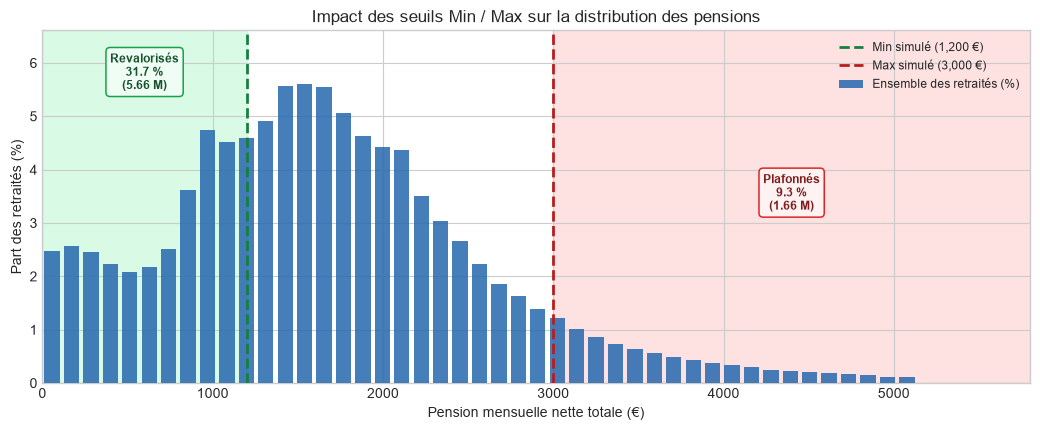

In [5]:
# === PARAMÈTRES MODIFIABLES (RÉPARTITION) ===
PENSION_MINIMUM = 1200.0           # Plancher en € nets/mois (mettre None pour désactiver)
CARRIERE_COMPLETE_SEULE = False    # True = réservé aux carrières complètes | False = universel (tous)
PENSION_MAXIMUM = 3000.0           # Plafond en € nets/mois (mettre None pour désactiver)
SEUIL_ECRETEMENT = None            # ex: 2500.0 pour réduire seulement une part au-delà d'un seuil
TAUX_ECRETEMENT_PCT = 0.0          # ex: 50.0 (%) appliqué au-delà de SEUIL_ECRETEMENT
REVALORISATION_GLOBALE_PCT = 0.0   # ex: -1.5 (%) pour simuler une baisse générale ou sous-indexation

params_rep_perso = ParametresReformeRepartition(
    nom="Votre scénario paramétré",
    pension_minimum=PENSION_MINIMUM,
    appliquer_min_carriere_complete_seule=CARRIERE_COMPLETE_SEULE,
    pension_maximum=PENSION_MAXIMUM,
    seuil_ecretement=SEUIL_ECRETEMENT,
    taux_ecretement_pct=TAUX_ECRETEMENT_PCT,
    revalorisation_globale_pct=REVALORISATION_GLOBALE_PCT,
)

scenarios = [
    params_rep_perso,
    ParametresReformeRepartition("Min 1 200 € (carrières complètes)", 1200.0, True, None),
    ParametresReformeRepartition("Min 1 200 € universel / Max 3 000 €", 1200.0, False, 3000.0),
    ParametresReformeRepartition("Min 1 400 € (carr. compl.) / Max 3 500 €", 1400.0, True, 3500.0),
    ParametresReformeRepartition("Écrêt. 50% > 2 500 € + Max 3 500 € (Min 1200 CC)", 1200.0, True, 3500.0, 2500.0, 50.0),
]

res_list = [simuler_reforme_repartition(micro, sc, ratio_net_brut=donnees.ratio_net_brut) for sc in scenarios]
df_sim_rep = pd.DataFrame(
    [
        {
            "Scénario": r["nom"],
            "Gagnants (%)": r["pct_gagnants"],
            "Gagnants (k)": r["eff_gagnants_k"],
            "Coût Min (Md€ net)": r["cout_min_net_mde"],
            "Perdants (%)": r["pct_perdants"],
            "Écon. Max (Md€ net)": r["economie_max_net_mde"],
            "Solde net (Md€/an)": r["solde_net_mde"],
            "Gini post": r["gini_post"],
        }
        for r in res_list
    ]
)
display(
    df_sim_rep.style.format(
        {
            "Gagnants (%)": "{:.1f} %",
            "Gagnants (k)": "{:,.0f}",
            "Coût Min (Md€ net)": "{:.2f}",
            "Perdants (%)": "{:.1f} %",
            "Écon. Max (Md€ net)": "{:.2f}",
            "Solde net (Md€/an)": "{:+.2f}",
            "Gini post": "{:.3f}",
        }
    )
)

if PENSION_MINIMUM:
    eq_univ = trouver_plafond_equilibre(micro, PENSION_MINIMUM, False, donnees.ratio_net_brut)
    eq_cc = trouver_plafond_equilibre(micro, PENSION_MINIMUM, True, donnees.ratio_net_brut)
    print(f"Solveur d'équilibre à 0 € pour financer un minimum à {PENSION_MINIMUM:,.0f} €/mois net :")
    print(f"  - Si universel (tous les retraités)   -> plafond max d'équilibre = {eq_univ:,.0f} €/mois net")
    print(f"  - Si réservé aux carrières complètes  -> plafond max d'équilibre = {eq_cc:,.0f} €/mois net")

# Graphique avec zones verte (revalorisés) et rouge clair (plafonnés)
fig, ax = plt.subplots(figsize=(10.5, 4.4))
tracer_distribution_min_max(
    ax,
    donnees,
    params_rep_perso,
    res_rep=res_list[0],
    titre="Impact des seuils Min / Max sur la distribution des pensions",
)
plt.tight_layout()
plt.show()


## 6. Simuler le passage vers une retraite par capitalisation

Dans un système **mixte** (répartition + capitalisation) :
- On conserve un **socle de $X\%$ en répartition** (la solidarité nationale, gérée comme aujourd'hui, ex. `40 %`).
- Les **$100 - X\%$ restants** (ex. `60 %`) ne servent plus à payer les retraités actuels : ils sont investis chaque mois sur le **compte personnel** du salarié jusqu'à ses 64 ans, où ils produisent des intérêts composés.

### Ce que vous pouvez paramétrer ci-dessous :
1. **`DUREE_TRANSITION_ANNEES`** : sur combien d'années on effectue le virage (`0` = bascule immédiate pour les cotisations futures ; `25` = montée en charge progressive). Tout ce qui a déjà été cotisé *avant* la réforme reste garanti à 100 % en répartition.
2. **`SOCLE_REPARTITION_PCT`** : le socle $X\%$ gardé en répartition à la fin de la transition.
3. **`DOTATION_NAISSANCE_ACTIVE` et `MONTANT_DOTATION_NAISSANCE`** : si activé, l'État verse un capital de départ à chaque nouveau-né (ex. 10 000 €), bloqué 64 ans jusqu'à sa retraite (coût annuel : ~6,1 Md€/an pour ~614 000 naissances).

### Comment lire les résultats ?
- **Montant en « € constants »** : c'est le pouvoir d'achat brut à la date où la personne partira à la retraite (en tenant compte de la croissance générale des salaires d'ici là).
- **Équivalent salaire d'aujourd'hui** : c'est le chiffre le plus parlant ! Il ramène la future pension sur l'échelle des salaires actuels (comme si vous gagniez 2 580 € net aujourd'hui). On peut ainsi comparer directement avec la retraite actuelle (~1 858 € net pour une carrière complète à 72 %).
- **Le besoin de financement transitoire (« double paiement »)** : pendant la transition, les cotisations placées en épargne individuelle manquent dans la caisse de répartition pour payer les retraités déjà à la retraite. C'est ce déficit temporaire qu'il faut financer (par l'impôt, la dette ou l'allongement d'activité) avant que les économies sur les nouvelles générations ne prennent le relais.


A. Résultat pour les Nouveaux Arrivants :


,Profil,Capital 64a (€ const.),Socle Rép. (€/mois),Rente Capi Cotis (€/mois),Rente Dot. Naiss. (€/mois),Pension Totale (€ const.),Équiv. salaire auj. (€),Gain vs 100% Rép.,Taux Remplacement
0,Nouveau-né (0 an) — SANS dotation,"1,154,458 €","1,411 €","6,402 €",0 €,"7,813 €","4,133 €",+122.5 %,160.2 %
1,Nouveau-né (0 an) — AVEC dotation,"1,321,738 €","1,411 €","6,402 €",928 €,"8,740 €","4,623 €",+148.9 %,179.2 %
2,Nouvel actif (22 ans aujourd'hui),"545,974 €","1,612 €","3,028 €",0 €,"4,640 €","3,055 €",+64.5 %,118.4 %


B. Résultat pour chaque tranche d'âge actuelle (Pyramide Eurostat France) :


,Tranche d'âge actuelle,Pop. (M),% Rép.,% Capi.,Capital 64a (€),Statu Quo (€ const.),Nouveau (€ const.),Équiv. sal. auj. (€),Gain vs Statu Quo
0,0 an (Nouveaux-nés),0.61 M,40 %,60 %,"1,321,738 €","3,512 €","8,740 €","4,623 €",+148.9 %
1,1 - 14 ans (Enfants),10.82 M,44 %,56 %,"973,796 €","3,250 €","6,811 €","3,887 €",+109.2 %
2,15 - 21 ans (Pré-actifs),5.83 M,52 %,48 %,"679,376 €","2,939 €","5,295 €","3,344 €",+80.0 %
3,22 - 29 ans (Jeunes actifs),6.32 M,62 %,38 %,"440,054 €","2,726 €","4,132 €","2,812 €",+51.4 %
4,30 - 39 ans,8.41 M,75 %,25 %,"226,967 €","2,490 €","3,127 €","2,330 €",+25.4 %
5,40 - 49 ans,8.56 M,88 %,12 %,"85,069 €","2,258 €","2,463 €","2,025 €",+9.0 %
6,50 - 59 ans,8.96 M,97 %,3 %,"18,228 €","2,043 €","2,080 €","1,891 €",+1.8 %
7,60 - 64 ans (Fin carrière),4.31 M,100 %,0 %,"1,164 €","1,896 €","1,898 €","1,859 €",+0.1 %
8,65+ ans (Déjà retraités),15.06 M,100 %,0 %,0 €,"1,858 €","1,858 €","1,858 €",+0.0 %


C. Trajectoire macroéconomique de la transition (« double paiement » et encours épargné) :


,annee_t,taux_capi_cotis_pct,flux_cotis_capi_mde,economie_rep_mde,besoin_transition_mde,cout_dotation_naissance_mde,encours_fonds_total_mde,encours_pct_pib
0,t + 0 ans,2.4 %,9.7 Md€,0.0 Md€,+9.7 Md€,6.1 Md€,16 Md€,1 %
5,t + 5 ans,14.4 %,61.4 Md€,0.4 Md€,+61.1 Md€,6.1 Md€,274 Md€,9 %
10,t + 10 ans,26.4 %,118.4 Md€,2.4 Md€,+116.0 Md€,6.1 Md€,890 Md€,28 %
15,t + 15 ans,38.4 %,181.0 Md€,7.3 Md€,+173.7 Md€,6.1 Md€,"1,955 Md€",58 %
25,t + 25 ans,60.0 %,312.4 Md€,31.2 Md€,+281.2 Md€,6.1 Md€,"5,785 Md€",154 %
35,t + 35 ans,60.0 %,345.1 Md€,80.2 Md€,+264.9 Md€,6.1 Md€,"11,441 Md€",277 %
45,t + 45 ans,60.0 %,381.2 Md€,154.3 Md€,+227.0 Md€,6.1 Md€,"18,086 Md€",396 %
65,t + 65 ans,60.0 %,465.1 Md€,341.9 Md€,+123.2 Md€,6.1 Md€,"30,619 Md€",549 %


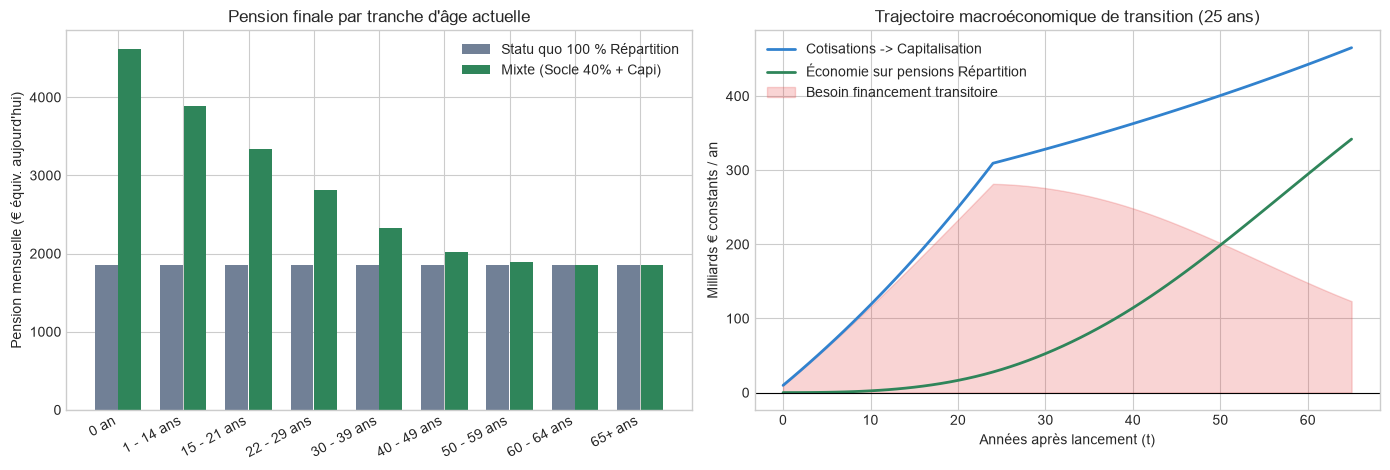

In [6]:
# === PARAMÈTRES MODIFIABLES (CAPITALISATION) ===
DUREE_TRANSITION_ANNEES = 25          # Nombre d'années pour atteindre la cible (0 = immédiat)
SOCLE_REPARTITION_PCT = 40.0          # X % maintenus en répartition à terme (le reste va en capitalisation)
DOTATION_NAISSANCE_ACTIVE = True      # True = verse un capital à la naissance | False = non
MONTANT_DOTATION_NAISSANCE = 10000.0  # Montant (€) versé à la naissance
DOTATION_ENFANTS_ACTUELS = False      # True = étend aussi la dotation aux mineurs (0-17 ans) déjà nés
RENDEMENT_REEL_PCT = 4.5              # Rendement annuel réel net d'inflation et de frais (%)
CROISSANCE_SALAIRES_REELLE_PCT = 1.0  # Croissance annuelle réelle des salaires (%)
SALAIRE_NET_MENSUEL_REF = 2580.0      # Salaire net mensuel de référence (€)

params_cap = ParametresCapitalisation(
    duree_transition_annees=DUREE_TRANSITION_ANNEES,
    socle_repartition_pct=SOCLE_REPARTITION_PCT,
    dotation_naissance_active=DOTATION_NAISSANCE_ACTIVE,
    montant_dotation_naissance=MONTANT_DOTATION_NAISSANCE,
    donner_dotation_aux_enfants_actuels=DOTATION_ENFANTS_ACTUELS,
    rendement_annuel_reel_pct=RENDEMENT_REEL_PCT,
    croissance_salaires_reelle_pct=CROISSANCE_SALAIRES_REELLE_PCT,
    salaire_net_mensuel_ref=SALAIRE_NET_MENSUEL_REF,
    salaire_brut_mensuel_ref=SALAIRE_NET_MENSUEL_REF * (3300.0 / 2580.0),
    ratio_net_brut_rente=donnees.ratio_net_brut,
)

# A. Nouveaux arrivants (Nouveau-né vs Nouvel actif à 22 ans)
na_items = [
    ("Nouveau-né (0 an) — SANS dotation", simuler_cohorte_individuelle(0, params_cap, False)),
    ("Nouveau-né (0 an) — AVEC dotation", simuler_cohorte_individuelle(0, params_cap, True)),
    ("Nouvel actif (22 ans aujourd'hui)", simuler_cohorte_individuelle(22, params_cap, False)),
]
df_na = pd.DataFrame(
    [
        {
            "Profil": lbl,
            "Capital 64a (€ const.)": r["capital_total_eur"],
            "Socle Rép. (€/mois)": r["pension_rep_eur"],
            "Rente Capi Cotis (€/mois)": r["rente_capi_cotis_eur"],
            "Rente Dot. Naiss. (€/mois)": r["rente_naissance_eur"],
            "Pension Totale (€ const.)": r["pension_totale_eur"],
            "Équiv. salaire auj. (€)": r["equiv_aujourdhui_eur"],
            "Gain vs 100% Rép.": r["gain_pct"],
            "Taux Remplacement": r["taux_remplacement_pct"],
        }
        for lbl, r in na_items
    ]
)
print("A. Résultat pour les Nouveaux Arrivants :")
display(
    df_na.style.format(
        {
            "Capital 64a (€ const.)": "{:,.0f} €",
            "Socle Rép. (€/mois)": "{:,.0f} €",
            "Rente Capi Cotis (€/mois)": "{:,.0f} €",
            "Rente Dot. Naiss. (€/mois)": "{:,.0f} €",
            "Pension Totale (€ const.)": "{:,.0f} €",
            "Équiv. salaire auj. (€)": "{:,.0f} €",
            "Gain vs 100% Rép.": "{:+.1f} %",
            "Taux Remplacement": "{:.1f} %",
        }
    )
)

# B. Chaque tranche d'âge actuelle (Eurostat)
df_tranches = simuler_tranches_age_eurostat(donnees.population_par_age, params_cap)
cols_tranches = df_tranches[
    [
        "tranche", "population_m", "part_effective_rep_pct", "part_effective_capi_pct",
        "capital_total_eur", "pension_statu_quo_eur", "pension_totale_eur",
        "equiv_aujourdhui_eur", "gain_pct",
    ]
].rename(
    columns={
        "tranche": "Tranche d'âge actuelle",
        "population_m": "Pop. (M)",
        "part_effective_rep_pct": "% Rép.",
        "part_effective_capi_pct": "% Capi.",
        "capital_total_eur": "Capital 64a (€)",
        "pension_statu_quo_eur": "Statu Quo (€ const.)",
        "pension_totale_eur": "Nouveau (€ const.)",
        "equiv_aujourdhui_eur": "Équiv. sal. auj. (€)",
        "gain_pct": "Gain vs Statu Quo",
    }
)
print("B. Résultat pour chaque tranche d'âge actuelle (Pyramide Eurostat France) :")
display(
    cols_tranches.style.format(
        {
            "Pop. (M)": "{:.2f} M",
            "% Rép.": "{:.0f} %",
            "% Capi.": "{:.0f} %",
            "Capital 64a (€)": "{:,.0f} €",
            "Statu Quo (€ const.)": "{:,.0f} €",
            "Nouveau (€ const.)": "{:,.0f} €",
            "Équiv. sal. auj. (€)": "{:,.0f} €",
            "Gain vs Statu Quo": "{:+.1f} %",
        }
    )
)

# C. Équilibre macroéconomique de la transition
df_macro = simuler_trajectoire_macro_transition(donnees, params_cap, horizon_annees=65)
df_jalons = df_macro[df_macro["annee_t"].isin([0, 5, 10, 15, 25, 35, 45, 65])].copy()
print("C. Trajectoire macroéconomique de la transition (« double paiement » et encours épargné) :")
display(
    df_jalons.style.format(
        {
            "annee_t": "t + {:.0f} ans",
            "taux_capi_cotis_pct": "{:.1f} %",
            "flux_cotis_capi_mde": "{:.1f} Md€",
            "economie_rep_mde": "{:.1f} Md€",
            "besoin_transition_mde": "{:+.1f} Md€",
            "cout_dotation_naissance_mde": "{:.1f} Md€",
            "encours_fonds_total_mde": "{:,.0f} Md€",
            "encours_pct_pib": "{:.0f} %",
        }
    )
)

# Graphiques de synthèse Capitalisation
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
x_i = np.arange(len(df_tranches))
ax1.bar(x_i - 0.18, df_tranches["statu_quo_equiv_aujourdhui_eur"], width=0.35, color="#718096", label="Statu quo 100 % Répartition")
ax1.bar(x_i + 0.18, df_tranches["equiv_aujourdhui_eur"], width=0.35, color="#2f855a", label=f"Mixte (Socle {SOCLE_REPARTITION_PCT:.0f}% + Capi)")
ax1.set_xticks(x_i)
ax1.set_xticklabels([t.split(" (")[0] for t in df_tranches["tranche"]], rotation=28, ha="right")
ax1.set_ylabel("Pension mensuelle (€ équiv. aujourd'hui)")
ax1.set_title("Pension finale par tranche d'âge actuelle")
ax1.legend()

ax2.plot(df_macro["annee_t"], df_macro["flux_cotis_capi_mde"], color="#3182ce", lw=2, label="Cotisations -> Capitalisation")
ax2.plot(df_macro["annee_t"], df_macro["economie_rep_mde"], color="#2f855a", lw=2, label="Économie sur pensions Répartition")
ax2.fill_between(
    df_macro["annee_t"], df_macro["besoin_transition_mde"], 0,
    where=(df_macro["besoin_transition_mde"] >= 0), color="#e53e3e", alpha=0.22,
    label="Besoin financement transitoire"
)
ax2.axhline(0, color="black", lw=0.8)
ax2.set_xlabel("Années après lancement (t)")
ax2.set_ylabel("Milliards € constants / an")
ax2.set_title(f"Trajectoire macroéconomique de transition ({DUREE_TRANSITION_ANNEES} ans)")
ax2.legend()
plt.tight_layout()
plt.show()
